In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": False,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})


import os
from os import listdir

# finding csv files
def find_csv_filenames( path_to_dir, suffix=".csv" ):
    filenames = listdir(path_to_dir)
    return [ filename for filename in filenames if filename.endswith( suffix ) ]

# function to read data

def read_data(filename):

    # check metadata entries
    with open(filename,'r') as f:
        lines=f.readlines()
        count=0
        for line in lines[1:]:
            if line[0]=='#':
                count+=1
            else:
                break

    # read data
    df = pd.read_csv(filename,skiprows=count+1)

    # add metadata
    attrs_dict = {}
    for i in range(1,count+1):
        key = lines[i][1:].strip().split(':')[0]
        entry = lines[i][1:].strip().split(':')[1]
        try:
            float(entry)
            #print("Metadata entry float")
            attrs_dict[key]=float(entry)
        except ValueError:
            #print("Metadata entry not a float")
            attrs_dict[key]=entry
    df.attrs = attrs_dict

    return df

In [3]:
# datafiles


path = '../../EXP_DATA/PF_Nguyen_2018/'
files = find_csv_filenames(path)

allPFs = np.array([])

for file in files:

    data = pd.read_csv(path+file)
    PF = np.array(data['PF'])

    first_residue = md.load('../../EXP_DATA/sequences_for_kint/' + file.split('.')[0] + '.pdb').topology.residue(0).resSeq
    residxs = np.array(data['Model_residue']).astype(int) - first_residue
    
    allPFs = np.append(allPFs,PF)

print(len(allPFs))
print(len(allscores))





/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/mdtraj/formats/pdb/pdbfile.py:206: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/mdtraj/formats/pdb/pdbfile.py:206: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(


2596
0


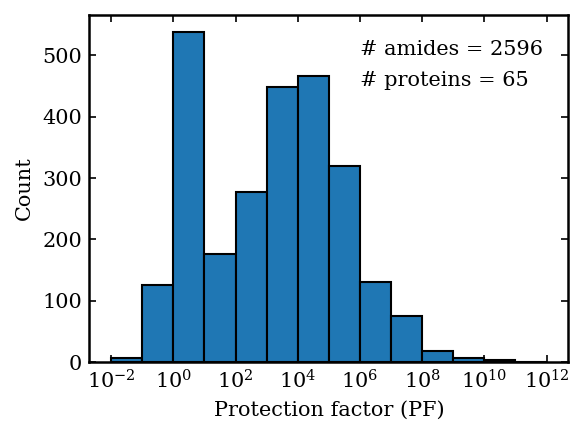

In [4]:
plt.figure(figsize = (4,3))

fontsize = 10

plt.hist(allPFs,bins=[1E-2,1E-1,1E-0,1E1,1E2,1E3,1E4,1E5,1E6,1E7,1E8,1E9,1E10,1E11,1E12],
        color = 'tab:blue', edgecolor = 'black')
plt.xscale('log')
plt.xticks(ticks = [1e-2,1e0,1e2,1e4,1e6,1e8,1e10,1e12])
plt.ylabel('Count',fontsize=fontsize)
plt.xlabel('Protection factor (PF)',fontsize=fontsize)

plt.text(x=1e6,y=500,s=f'# amides = {len(allPFs)}')
plt.text(x=1e6,y=450,s=f'# proteins = {len(files)}')

plt.tight_layout()
plt.savefig('PF_histogram.png',dpi=300)


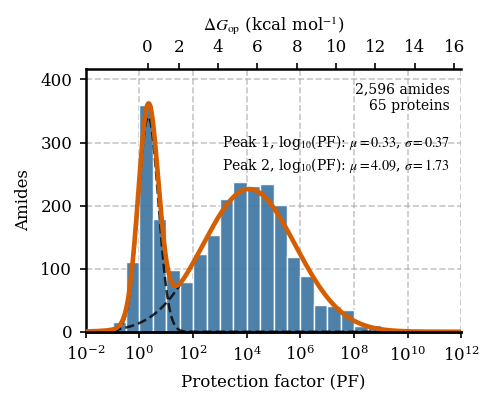

In [9]:

from sklearn.mixture import GaussianMixture

# --------------------------------------------------
# High-contrast, colour-blind-friendly colours
# --------------------------------------------------
HIST_COLOR = "#3B73A1"       # deep muted blue
TOTAL_FIT_COLOR = "#D55E00"  # vermillion
COMPONENT_COLOR = "#000000"  # black
#HIST_COLOR = "tab:blue"       # deep muted blue
#TOTAL_FIT_COLOR = "tab:red"  # vermillion
#COMPONENT_COLOR = "#000000"  # black

# --------------------------------------------------
# Prepare data
# --------------------------------------------------
allPFs = np.asarray(allPFs, dtype=float)
allPFs = allPFs[np.isfinite(allPFs) & (allPFs > 0)]

logPF = np.log10(allPFs).reshape(-1, 1)

# --------------------------------------------------
# Fit Gaussian mixture model in log10(PF) space
# --------------------------------------------------
models = [
    GaussianMixture(
        n_components=n,
        covariance_type="full",
        random_state=1
    ).fit(logPF)
    for n in range(1, 6)
]

bics = [model.bic(logPF) for model in models]
gmm = models[np.argmin(bics)]

# Sort components from low to high PF
order = np.argsort(gmm.means_.ravel())
weights = gmm.weights_[order]
means = gmm.means_.ravel()[order]
sigmas = np.sqrt(gmm.covariances_.reshape(-1)[order])

# --------------------------------------------------
# Histogram and fit settings
# --------------------------------------------------
fontsize = 8

log_bins = np.arange(-2, 12.5, 0.5)
pf_bins = 10**log_bins
bin_width = np.diff(log_bins)[0]

x_log = np.linspace(log_bins.min(), log_bins.max(), 2000)
x_pf = 10**x_log

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(3.4, 2.8))

ax.hist(
    allPFs,
    bins=pf_bins,
    color=HIST_COLOR,
    edgecolor="white",
    linewidth=0.7,
    alpha=0.9,
    zorder=1
)

# --------------------------------------------------
# Total Gaussian-mixture fit
# --------------------------------------------------
log_density = gmm.score_samples(x_log.reshape(-1, 1))
mixture_density = np.exp(log_density)
mixture_counts = mixture_density * len(allPFs) * bin_width

ax.plot(
    x_pf,
    mixture_counts,
    color=TOTAL_FIT_COLOR,
    linewidth=2.2,
    zorder=4
)

# --------------------------------------------------
# Individual Gaussian components
# --------------------------------------------------
for weight, mu, sigma in zip(weights, means, sigmas):
    component_density = (
        weight
        * np.exp(-0.5 * ((x_log - mu) / sigma) ** 2)
        / (sigma * np.sqrt(2 * np.pi))
    )

    component_counts = component_density * len(allPFs) * bin_width

    ax.plot(
        x_pf,
        component_counts,
        color=COMPONENT_COLOR,
        linestyle="--",
        linewidth=1.2,
        alpha=0.8,
        zorder=3
    )

# --------------------------------------------------
# Bottom axis: protection factor
# --------------------------------------------------
ax.set_xscale("log")
ax.set_xlim(1e-2, 1e12)
ax.set_ylim(0, np.max(mixture_counts) * 1.15)

ax.set_xticks([
    1e-2, 1e0, 1e2, 1e4,
    1e6, 1e8, 1e10, 1e12
])

ax.set_xlabel("Protection factor (PF)", fontsize=fontsize)
ax.set_ylabel("Amides", fontsize=fontsize)

# --------------------------------------------------
# Dataset and Gaussian annotations
# --------------------------------------------------
peak_text = "\n".join(
    [
        rf"Peak {i}, log$_{{10}}$(PF): "
        rf"$\mu={mu:.2f}$, $\sigma={sigma:.2f}$"
        for i, (mu, sigma) in enumerate(zip(means, sigmas), start=1)
    ]
)

annotation_text = (
    f"{len(allPFs):,} amides\n"
    f"{len(files)} proteins\n\n"
    f"{peak_text}"
)

ax.text(
    0.97,
    0.95,
    annotation_text,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=6.7,
    color="black",
    linespacing=1.25,
    zorder=6
)

# --------------------------------------------------
# Formatting
# --------------------------------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    top=False,
    right=False,
    direction="out",
    length=3,
    width=0.8,
    labelsize=fontsize
)

ax.grid(True, which="major", axis="both")
ax.set_axisbelow(True)

# --------------------------------------------------
# Top axis: opening free energy
# --------------------------------------------------
temperature = 298.15
R = 1.987204258e-3  # kcal mol^-1 K^-1
RT = R * temperature

def dG_to_pf(delta_g):
    delta_g = np.asarray(delta_g, dtype=float)
    return 1.0 + np.exp(delta_g / RT)

ax_top = ax.twiny()
ax_top.set_xscale("log")
ax_top.set_xlim(ax.get_xlim())

dG_ticks = np.arange(0, 17, 2)
pf_tick_positions = dG_to_pf(dG_ticks)

xmin, xmax = ax.get_xlim()
mask = (pf_tick_positions >= xmin) & (pf_tick_positions <= xmax)

ax_top.set_xticks(pf_tick_positions[mask])
ax_top.set_xticklabels([
    f"{value:g}" for value in dG_ticks[mask]
])

ax_top.set_xlabel(
    r"$\Delta G_{\mathrm{op}}$ (kcal mol$^{-1}$)",
    fontsize=fontsize
)

ax_top.tick_params(
    axis="x",
    which="both",
    top=True,
    bottom=False,
    direction="out",
    length=3,
    width=0.8,
    labelsize=fontsize
)

ax_top.spines["right"].set_visible(False)
ax_top.spines["left"].set_visible(False)
ax_top.grid(False)

# --------------------------------------------------
# Save
# --------------------------------------------------
fig.tight_layout()

fig.savefig(
    "PF_histogram.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.show()

0.46284898000714153
0.39430097799140285


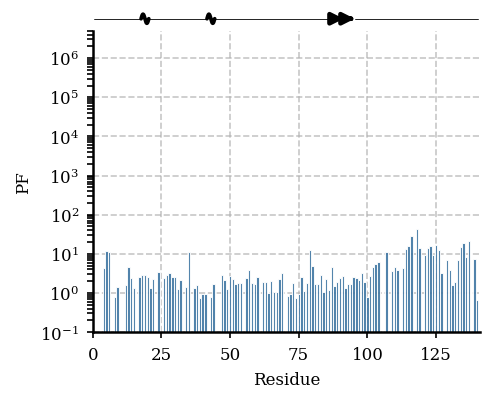

In [40]:
# --------------------------------------------------
# Representative protein
# --------------------------------------------------
protein = "aSyn"

HIST_COLOR = "#3B73A1"
SS_COLOR = "black"
fontsize = 8

# --------------------------------------------------
# Load PF data
# --------------------------------------------------
data = pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")
data = data.dropna(subset=["Model_residue", "PF"]).copy()
data = data[np.isfinite(data["PF"]) & (data["PF"] > 0)]
data = data.sort_values("Model_residue")

print(np.mean(np.log10(data["PF"])))
print(np.std(np.log10(data["PF"])))

# --------------------------------------------------
# Load structure and calculate DSSP
# --------------------------------------------------
structure = md.load(f"../../MD_DATA/{protein}/protein.pdb")
dssp = md.compute_dssp(structure, simplified=True)[0]

structure_residues = np.array([
    residue.resSeq
    for residue in structure.topology.residues
])

# --------------------------------------------------
# Find continuous secondary-structure segments
# --------------------------------------------------
segments = []

segment_start = structure_residues[0]
segment_end = structure_residues[0]
segment_type = dssp[0]

for residue, assignment in zip(structure_residues[1:], dssp[1:]):

    if assignment == segment_type and residue == segment_end + 1:
        segment_end = residue

    else:
        segments.append(
            (segment_start, segment_end, segment_type)
        )

        segment_start = residue
        segment_end = residue
        segment_type = assignment

segments.append(
    (segment_start, segment_end, segment_type)
)

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(3.4, 2.8))

ax.bar(
    data["Model_residue"],
    data["PF"],
    width=0.85,
    color=HIST_COLOR,
    edgecolor="white",
    linewidth=0.5,
    alpha=0.9,
    zorder=2
)

ax.set_yscale("log")
ax.set_ylim(1e-1, 5e6)

# Keep x-range over the full protein
xmin = structure_residues.min() - 1
xmax = structure_residues.max() + 1
ax.set_xlim(xmin, xmax)

ax.set_xlabel("Residue", fontsize=fontsize)
ax.set_ylabel("PF", fontsize=fontsize)

# --------------------------------------------------
# Secondary-structure annotation
# --------------------------------------------------
ss_transform = ax.get_xaxis_transform()
ss_y = 1.04

for start, end, assignment in segments:

    x0 = start - 0.4
    x1 = end + 0.4

    if assignment == "C":

        # Coil: thin straight line
        ax.plot(
            [x0, x1],
            [ss_y, ss_y],
            transform=ss_transform,
            color=SS_COLOR,
            linewidth=0.4,
            solid_capstyle="round",
            clip_on=False,
            zorder=5
        )

    elif assignment == "E":

        # Beta strand: thick arrow
        ax.annotate(
            "",
            xy=(x1, ss_y),
            xytext=(x0, ss_y),
            xycoords=ss_transform,
            textcoords=ss_transform,
            arrowprops=dict(
                arrowstyle="-|>",
                color=SS_COLOR,
                linewidth=2.2,
                shrinkA=0,
                shrinkB=0,
                mutation_scale=11
            ),
            zorder=6
        )

    elif assignment == "H":

        # Alpha helix: thick wavy line
        x = np.linspace(x0, x1, 300)

        n_turns = max(
            1,
            int(np.ceil((x1 - x0) / 4.0))
        )

        y = ss_y + 0.015 * np.sin(
            np.linspace(
                0,
                2 * np.pi * n_turns,
                x.size
            )
        )

        ax.plot(
            x,
            y,
            transform=ss_transform,
            color=SS_COLOR,
            linewidth=1.8,
            solid_capstyle="round",
            clip_on=False,
            zorder=6
        )

# --------------------------------------------------
# Formatting
# --------------------------------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    top=False,
    right=False,
    direction="out",
    length=3,
    width=0.8,
    labelsize=fontsize
)

ax.grid(
    True,
    which="major",
    axis="both"
)

ax.set_axisbelow(True)

# --------------------------------------------------
# Save
# --------------------------------------------------
fig.tight_layout()

plt.savefig(
    f"PF_vs_res_{protein}.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()

3.4769258220274333
1.7626641176169782


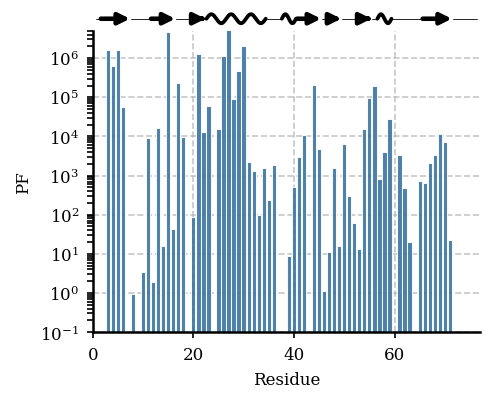

In [39]:
# --------------------------------------------------
# Representative protein
# --------------------------------------------------
protein = "Ubiquitin"

HIST_COLOR = "#3B73A1"
SS_COLOR = "black"
fontsize = 8

# --------------------------------------------------
# Load PF data
# --------------------------------------------------
data = pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")
data = data.dropna(subset=["Model_residue", "PF"]).copy()
data = data[np.isfinite(data["PF"]) & (data["PF"] > 0)]
data = data.sort_values("Model_residue")

print(np.mean(np.log10(data["PF"])))
print(np.std(np.log10(data["PF"])))

# --------------------------------------------------
# Load structure and calculate DSSP
# --------------------------------------------------
structure = md.load(f"../../MD_DATA/{protein}/protein.pdb")
dssp = md.compute_dssp(structure, simplified=True)[0]

structure_residues = np.array([
    residue.resSeq
    for residue in structure.topology.residues
])

# --------------------------------------------------
# Find continuous secondary-structure segments
# --------------------------------------------------
segments = []

segment_start = structure_residues[0]
segment_end = structure_residues[0]
segment_type = dssp[0]

for residue, assignment in zip(structure_residues[1:], dssp[1:]):

    if assignment == segment_type and residue == segment_end + 1:
        segment_end = residue

    else:
        segments.append(
            (segment_start, segment_end, segment_type)
        )

        segment_start = residue
        segment_end = residue
        segment_type = assignment

segments.append(
    (segment_start, segment_end, segment_type)
)

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(3.4, 2.8))

ax.bar(
    data["Model_residue"],
    data["PF"],
    width=0.85,
    color=HIST_COLOR,
    edgecolor="white",
    linewidth=0.5,
    alpha=0.9,
    zorder=2
)

ax.set_yscale("log")
ax.set_ylim(1e-1, 5e6)

# Keep x-range over the full protein
xmin = structure_residues.min() - 1
xmax = structure_residues.max() + 1
ax.set_xlim(xmin, xmax)

ax.set_xlabel("Residue", fontsize=fontsize)
ax.set_ylabel("PF", fontsize=fontsize)

# --------------------------------------------------
# Secondary-structure annotation
# --------------------------------------------------
ss_transform = ax.get_xaxis_transform()
ss_y = 1.04

for start, end, assignment in segments:

    x0 = start - 0.4
    x1 = end + 0.4

    if assignment == "C":

        # Coil: thin straight line
        ax.plot(
            [x0, x1],
            [ss_y, ss_y],
            transform=ss_transform,
            color=SS_COLOR,
            linewidth=0.4,
            solid_capstyle="round",
            clip_on=False,
            zorder=5
        )

    elif assignment == "E":

        # Beta strand: thick arrow
        ax.annotate(
            "",
            xy=(x1, ss_y),
            xytext=(x0, ss_y),
            xycoords=ss_transform,
            textcoords=ss_transform,
            arrowprops=dict(
                arrowstyle="-|>",
                color=SS_COLOR,
                linewidth=2.2,
                shrinkA=0,
                shrinkB=0,
                mutation_scale=11
            ),
            zorder=6
        )

    elif assignment == "H":

        # Alpha helix: thick wavy line
        x = np.linspace(x0, x1, 300)

        n_turns = max(
            1,
            int(np.ceil((x1 - x0) / 4.0))
        )

        y = ss_y + 0.015 * np.sin(
            np.linspace(
                0,
                2 * np.pi * n_turns,
                x.size
            )
        )

        ax.plot(
            x,
            y,
            transform=ss_transform,
            color=SS_COLOR,
            linewidth=1.8,
            solid_capstyle="round",
            clip_on=False,
            zorder=6
        )

# --------------------------------------------------
# Formatting
# --------------------------------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    top=False,
    right=False,
    direction="out",
    length=3,
    width=0.8,
    labelsize=fontsize
)

ax.grid(
    True,
    which="major",
    axis="both"
)

ax.set_axisbelow(True)

# --------------------------------------------------
# Save
# --------------------------------------------------
fig.tight_layout()

plt.savefig(
    f"PF_vs_res_{protein}.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()

In [7]:
# approximate rates

# datafiles

# correct rates to these values:
ref_conc = 1.0 # 100% H2O or 100% D2O
ref_pH = 7.4
ref_T = 298.0
R = 0.008314 # kJ mol-1, gas constant
Ea = 81.4 # kJ mol-1, activation energy, https://doi.org/10.1021/acs.jpcb.4c03967

path = '../../EXP_DATA/'
files = find_csv_filenames(path)

allrates = np.array([])

for file in files:

    data = read_data(path+file)
    pH = data.attrs['pH']
    T = data.attrs['temp']
    conc = float(data.attrs['conc'])
    rates = data['kobs']

    corr_conc = ref_conc/conc
    corr_pH = 10**(ref_pH-pH)
    corr_T = np.exp(-(Ea / R) * (1/ref_T - 1/T))

    final_rates = rates * corr_conc * corr_pH * corr_T
    
    allrates = np.append(allrates,final_rates)

len(allrates)





2919

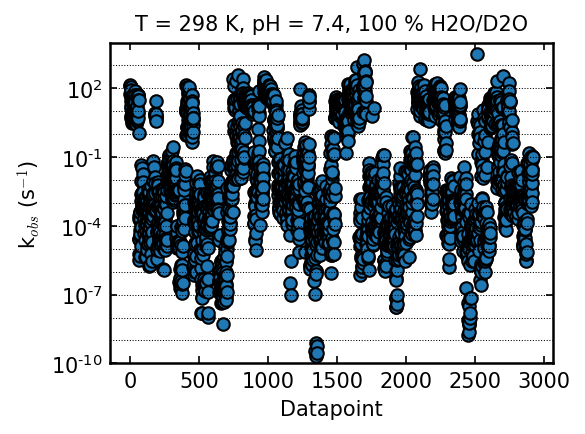

In [8]:
plt.figure(figsize = (4,3))

fontsize = 10

plt.scatter(np.arange(len(allrates)),allrates,color='tab:blue',edgecolor='black')
plt.yscale('log')
plt.ylabel('k$_{obs}$ (s$^{-1}$)',fontsize=fontsize)
plt.xlabel('Datapoint',fontsize=fontsize)
plt.ylim(10**(-10),10e3)
plt.title('T = 298 K, pH = 7.4, 100 % H2O/D2O',fontsize=fontsize)

for level in np.arange(-10.,5.):
    plt.axhline(10**level,color='black',linestyle='dotted',linewidth=0.5)

plt.tight_layout()
plt.savefig('kobs_expdata.png',dpi=300)

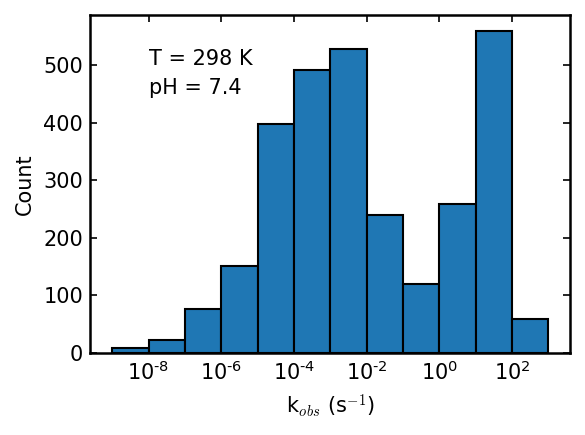

In [9]:
plt.figure(figsize = (4,3))

fontsize = 10

plt.hist(allrates,bins=[1E-9,1E-8,1E-7,1E-6,1E-5,1E-4,1E-3,1E-2,1E-1,1E-0,1E1,1E2,1E3],
        color = 'tab:blue', edgecolor = 'black')
plt.xscale('log')
plt.ylabel('Count',fontsize=fontsize)
plt.xlabel('k$_{obs}$ (s$^{-1}$)',fontsize=fontsize)

plt.text(x=1e-8,y=500,s='T = 298 K')
plt.text(x=1e-8,y=450,s='pH = 7.4')


plt.tight_layout()
plt.savefig('kobs_histogram.png',dpi=300)
